# Homework 7

**Name:** Nakul Kumbria

**GitHub Username:** nakicool007

**USC ID:** 6748597520

## Setup

In [ ]:
from pathlib import Path
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, confusion_matrix,
    ConfusionMatrixDisplay, multilabel_confusion_matrix, roc_curve, roc_auc_score)

SEED = 42
N_JOBS = 4  # number of parallel CV jobs
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.14.4 | scikit-learn: 1.9.1


## Question 1: Multi-class and Multi-label SVM Classification

## 1(a) Load the data and split it

The dataset has 7,195 rows and 22 MFCC features. Each row has three labels: Family, Genus, and Species. I used the CSV file in the data folder and left out RecordID because it identifies a recording rather than an acoustic feature.

I randomly selected 70% of the rows for training with `random_state=42`. This gave 5,036 training rows and 2,159 test rows. I also checked for missing values and made sure every class appeared in both sets.

The MFCC values are already normalized between -1 and 1, but this is different from standardizing each feature. I compare both versions in part (b)(ii).

In [ ]:
df = pd.read_csv(ROOT / 'data' / 'anuran_calls_data' / 'Frogs_MFCCs.csv')
labels = ['Family', 'Genus', 'Species']
features = [c for c in df.columns if c.startswith('MFCCs_')]
assert len(df) == 7195 and len(features) == 22
assert not df.isna().any().any()
X = df[features].astype(float)
Y = df[labels]
train_idx, test_idx = train_test_split(np.arange(len(df)), train_size=0.7, random_state=SEED)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = Y.iloc[train_idx], Y.iloc[test_idx]
print(f'Dataset: {df.shape}; train: {X_train.shape}; test: {X_test.shape}')
print('Constant MFCC columns:', X.columns[X.nunique() == 1].tolist())
print('RecordIDs shared by train/test:', len(set(df.iloc[train_idx].RecordID) & set(df.iloc[test_idx].RecordID)))
for label in labels:
    assert set(y_train[label]) == set(y_test[label]) == set(Y[label])
    assert y_train[label].value_counts().min() >= 10
    display(pd.DataFrame({'all': Y[label].value_counts(),
                          'train': y_train[label].value_counts(),
                          'test': y_test[label].value_counts()}).rename_axis(label))

Dataset: (7195, 26); train: (5036, 22); test: (2159, 22)
Constant MFCC columns: []
RecordIDs shared by train/test: 57


,all,train,test
Family,,,
Leptodactylidae,4420,3073,1347
Hylidae,2165,1542,623
Dendrobatidae,542,380,162
Bufonidae,68,41,27


,all,train,test
Genus,,,
Adenomera,4150,2899,1251
Ameerega,542,380,162
Dendropsophus,310,226,84
Hypsiboas,1593,1125,468
Leptodactylus,270,174,96
Osteocephalus,114,80,34
Rhinella,68,41,27
Scinax,148,111,37


,all,train,test
Species,,,
AdenomeraAndre,672,452,220
AdenomeraHylaedactylus,3478,2447,1031
Ameeregatrivittata,542,380,162
HylaMinuta,310,226,84
HypsiboasCinerascens,472,337,135
HypsiboasCordobae,1121,788,333
LeptodactylusFuscus,270,174,96
OsteocephalusOophagus,114,80,34
Rhinellagranulosa,68,41,27


## 1(b)(i) Evaluation measures

**Exact match** is the fraction of rows where all three labels are correct:

$$\text{Exact match} = \frac{1}{n}\sum_{i=1}^{n} I(y_i=\hat y_i).$$

**Hamming loss** is the fraction of individual label predictions that are wrong:

$$\text{Hamming loss} = \frac{1}{3n}\sum_{i=1}^{n}\sum_{j=1}^{3} I(y_{ij}\ne\hat y_{ij}).$$

I use **Hamming score = 1 - Hamming loss**. For example, if two out of three labels are correct for a row, its exact-match score is 0 and its Hamming score is 2/3. Higher exact match and Hamming score are better; lower Hamming loss is better.

I calculate these directly on the three categorical outputs. This avoids changing the meaning of Hamming loss by expanding the labels into 22 binary columns. Here, Hamming score means label accuracy rather than Jaccard similarity.

In [ ]:
def multioutput_metrics(truth, pred):
    truth, pred = np.asarray(truth), np.asarray(pred)
    assert truth.shape == pred.shape and truth.ndim == 2
    correct = truth == pred
    return {'exact_match': correct.all(axis=1).mean(),
            'exact_match_loss': 1 - correct.all(axis=1).mean(),
            'hamming_score': correct.mean(), 'hamming_loss': (~correct).mean()}

models, predictions, margins, tuning_rows = {}, {}, {}, []
cv_results = {}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def tune_output(model_name, label, estimator, param_grid):
    search = GridSearchCV(estimator, param_grid, cv=cv, scoring='accuracy',
                          refit=True, n_jobs=N_JOBS, error_score='raise',
                          return_train_score=False, pre_dispatch=N_JOBS)
    search.fit(X_train, y_train[label])
    result = pd.DataFrame(search.cv_results_)
    cv_results[(model_name, label)] = result
    tuning_rows.append({'model': model_name, 'label': label,
                        'best_parameters': str(search.best_params_),
                        'CV_accuracy': search.best_score_,
                        'CV_std': result.loc[search.best_index_, 'std_test_score']})
    print(model_name, label, search.best_params_, f'CV={search.best_score_:.5f}', flush=True)
    return search.best_estimator_

def save_independent(model_name, fitted):
    models[model_name] = fitted
    predictions[model_name] = np.column_stack([fitted[l].predict(X_test) for l in labels])
    margins[model_name] = {l: fitted[l].decision_function(X_test) for l in labels}

def summary_table():
    rows = []
    for name, pred in predictions.items():
        row = {'model': name, **multioutput_metrics(y_test, pred)}
        row.update({f'{l}_accuracy': accuracy_score(y_test[l], pred[:, j])
                    for j, l in enumerate(labels)})
        rows.append(row)
    return pd.DataFrame(rows).set_index('model')

## 1(b)(ii) SVM with a Gaussian kernel

I trained a separate classifier for each label and used `OneVsRestClassifier` to handle the classes within each label. Setting `SVC`'s decision-function shape to `ovr` alone would still train one-versus-one models internally.

The Gaussian kernel is

$$K(x,z)=\exp(-\gamma\|x-z\|^2), \qquad \gamma=\frac{1}{2\sigma^2}.$$

I searched over:

- $C$: 0.1, 1, 10, 100
- $\gamma$: 0.01, 0.1, 1, 10

For each label, I selected the pair with the highest average accuracy in 10-fold cross-validation. Larger $C$ puts more weight on training errors, while larger $\gamma$ gives a narrower kernel. The output also gives the corresponding width $\sigma$.

I ran this once with the original features and once with standardized features. The scaler is inside the pipeline so it is fitted only on the training portion of each fold. A parameter at the edge of the grid might improve with a wider search.

In [ ]:
rbf_grid = {'svm__estimator__C': [0.1, 1, 10, 100],
            'svm__estimator__gamma': [0.01, 0.1, 1, 10]}
for name, scale in [('RBF_raw', False), ('RBF_standardized', True)]:
    fitted = {}
    for label in labels:
        pipeline = Pipeline([('scale', StandardScaler() if scale else 'passthrough'),
            ('svm', OneVsRestClassifier(SVC(kernel='rbf', cache_size=128), n_jobs=1))])
        fitted[label] = tune_output(name, label, pipeline, rbf_grid)
    save_independent(name, fitted)
display(pd.DataFrame(tuning_rows))
display(summary_table().round(6))
for name in ['RBF_raw', 'RBF_standardized']:
    for label in labels:
        svm = models[name][label].named_steps['svm'].estimator
        boundary = svm.C in (0.1, 100) or svm.gamma in (0.01, 10)
        print(f'{name}/{label}: C={svm.C}, gamma={svm.gamma}, sigma={np.sqrt(1/(2*svm.gamma)):.4f}; grid boundary={boundary}')

RBF_raw Family {'svm__estimator__C': 100, 'svm__estimator__gamma': 1} CV=0.99146 (completed search reused)


RBF_raw Genus {'svm__estimator__C': 10, 'svm__estimator__gamma': 1} CV=0.99106 (completed search reused)


RBF_raw Species {'svm__estimator__C': 10, 'svm__estimator__gamma': 1} CV=0.99007 (completed search reused)


RBF_standardized Family {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1} CV=0.99047 (completed search reused)


RBF_standardized Genus {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1} CV=0.98908 (completed search reused)


RBF_standardized Species {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1} CV=0.98888 (completed search reused)


,model,label,best_parameters,CV_accuracy,CV_std
0,RBF_raw,Family,"{'svm__estimator__C': 100, 'svm__estimator__ga...",0.991460,0.003773
1,RBF_raw,Genus,"{'svm__estimator__C': 10, 'svm__estimator__gam...",0.991064,0.003108
2,RBF_raw,Species,"{'svm__estimator__C': 10, 'svm__estimator__gam...",0.990074,0.004693
3,RBF_standardized,Family,"{'svm__estimator__C': 10, 'svm__estimator__gam...",0.990468,0.006395
4,RBF_standardized,Genus,"{'svm__estimator__C': 10, 'svm__estimator__gam...",0.989078,0.004096
5,RBF_standardized,Species,"{'svm__estimator__C': 10, 'svm__estimator__gam...",0.988880,0.004458


,exact_match,exact_match_loss,hamming_score,hamming_loss,Family_accuracy,Genus_accuracy,Species_accuracy
model,,,,,,,
RBF_raw,0.987494,0.012506,0.992280,0.007720,0.995831,0.990273,0.990736
RBF_standardized,0.986568,0.013432,0.989964,0.010036,0.993516,0.988421,0.987957


RBF_raw/Family: C=100, gamma=1, sigma=0.7071; grid boundary=True
RBF_raw/Genus: C=10, gamma=1, sigma=0.7071; grid boundary=False
RBF_raw/Species: C=10, gamma=1, sigma=0.7071; grid boundary=False
RBF_standardized/Family: C=10, gamma=0.1, sigma=2.2361; grid boundary=False
RBF_standardized/Genus: C=10, gamma=0.1, sigma=2.2361; grid boundary=False
RBF_standardized/Species: C=10, gamma=0.1, sigma=2.2361; grid boundary=False


## 1(b)(iii) L1-penalized SVM

For this part I used a linear SVM with an L1 penalty. L1 can set some feature weights to zero, giving a sparse model.

I standardized the features and used `LinearSVC(penalty='l1', dual=False, loss='squared_hinge')` with one-versus-rest classification. I selected $C$ from 0.001, 0.01, 0.1, 1, 10, and 100 using 10-fold cross-validation for each label.

The iteration limit is large because some fits took longer to converge. Convergence warnings are treated as errors so an unfinished fit is not used in the comparison.

In [5]:
linear_grid = {'svm__estimator__C': [0.001, 0.01, 0.1, 1, 10, 100]}
def linear_pipeline(balanced=False):
    return Pipeline([('scale', StandardScaler()),
        ('svm', OneVsRestClassifier(LinearSVC(penalty='l1', loss='squared_hinge',
            dual=False, C=1, class_weight='balanced' if balanced else None,
            max_iter=1000000, tol=1e-4, random_state=SEED), n_jobs=1))])

fitted = {}
for label in labels:
    fitted[label] = tune_output('L1_linear', label, linear_pipeline(), linear_grid)
save_independent('L1_linear', fitted)
display(pd.DataFrame(tuning_rows).query("model == 'L1_linear'"))
display(summary_table().round(6))
for label in labels:
    coefficients = np.vstack([e.coef_ for e in fitted[label].named_steps['svm'].estimators_])
    print(label, ':', np.count_nonzero(coefficients), 'nonzero coefficients out of', coefficients.size)

L1_linear Family {'svm__estimator__C': 10} CV=0.94122 (completed search reused)


L1_linear Genus {'svm__estimator__C': 100} CV=0.95155 (completed search reused)


L1_linear Species {'svm__estimator__C': 10} CV=0.96068 (completed search reused)


,model,label,best_parameters,CV_accuracy,CV_std
6,L1_linear,Family,{'svm__estimator__C': 10},0.941223,0.007552
7,L1_linear,Genus,{'svm__estimator__C': 100},0.951551,0.006143
8,L1_linear,Species,{'svm__estimator__C': 10},0.960682,0.008652


,exact_match,exact_match_loss,hamming_score,hamming_loss,Family_accuracy,Genus_accuracy,Species_accuracy
model,,,,,,,
RBF_raw,0.987494,0.012506,0.992280,0.007720,0.995831,0.990273,0.990736
RBF_standardized,0.986568,0.013432,0.989964,0.010036,0.993516,0.988421,0.987957
L1_linear,0.912459,0.087541,0.943029,0.056971,0.928208,0.941640,0.959240


Family : 88 nonzero coefficients out of 88
Genus : 176 nonzero coefficients out of 176
Species : 220 nonzero coefficients out of 220


## 1(b)(iv) Handling class imbalance

I used **balanced class weights** as the alternative to SMOTE allowed in the question. This gives errors on less frequent classes more weight instead of adding synthetic data.

For each binary one-versus-rest classifier, the weight for class $c$ is $n/(2n_c)$. These weights are calculated using only the data in that training fold.

I repeated the standardized L1 experiment and selected $C$ using the same 10-fold accuracy score. Besides overall accuracy, I compared macro recall and recall for the rarest class. This helps show whether balancing improves the minority classes even if overall accuracy decreases.

In [6]:
fitted = {}
for label in labels:
    fitted[label] = tune_output('L1_balanced', label, linear_pipeline(True), linear_grid)
save_independent('L1_balanced', fitted)
display(pd.DataFrame(tuning_rows).query("model == 'L1_balanced'"))
imbalance_rows = []
for name in ['L1_linear', 'L1_balanced']:
    for j, label in enumerate(labels):
        classes = models[name][label].named_steps['svm'].classes_
        minority = y_train[label].value_counts().idxmin()
        recall = precision_recall_fscore_support(y_test[label], predictions[name][:, j],
            labels=classes, zero_division=0)[1]
        imbalance_rows.append({'model': name, 'label': label,
            'accuracy': accuracy_score(y_test[label], predictions[name][:, j]),
            'macro_recall': balanced_accuracy_score(y_test[label], predictions[name][:, j]),
            'minority_class': minority,
            'minority_recall': recall[list(classes).index(minority)]})
imbalance_table = pd.DataFrame(imbalance_rows)
display(imbalance_table.round(6))
display(summary_table().round(6))

L1_balanced Family {'svm__estimator__C': 100} CV=0.93189 (completed search reused)


L1_balanced Genus {'svm__estimator__C': 1} CV=0.93607 (completed search reused)


L1_balanced Species {'svm__estimator__C': 1} CV=0.95652 (completed search reused)


,model,label,best_parameters,CV_accuracy,CV_std
9,L1_balanced,Family,{'svm__estimator__C': 100},0.931892,0.008874
10,L1_balanced,Genus,{'svm__estimator__C': 1},0.936067,0.011840
11,L1_balanced,Species,{'svm__estimator__C': 1},0.956517,0.010122


,model,label,accuracy,macro_recall,minority_class,minority_recall
0,L1_linear,Family,0.928208,0.690223,Bufonidae,0.000000
1,L1_linear,Genus,0.941640,0.769036,Rhinella,0.259259
2,L1_linear,Species,0.959240,0.894759,Rhinellagranulosa,0.888889
3,L1_balanced,Family,0.921260,0.906626,Bufonidae,0.851852
4,L1_balanced,Genus,0.930523,0.893976,Rhinella,0.925926
5,L1_balanced,Species,0.956461,0.911821,Rhinellagranulosa,0.962963


,exact_match,exact_match_loss,hamming_score,hamming_loss,Family_accuracy,Genus_accuracy,Species_accuracy
model,,,,,,,
RBF_raw,0.987494,0.012506,0.992280,0.007720,0.995831,0.990273,0.990736
RBF_standardized,0.986568,0.013432,0.989964,0.010036,0.993516,0.988421,0.987957
L1_linear,0.912459,0.087541,0.943029,0.056971,0.928208,0.941640,0.959240
L1_balanced,0.895785,0.104215,0.936082,0.063918,0.921260,0.930523,0.956461


# Question 2: K-Means Clustering

I used the whole dataset without a train-test split and repeated parts (a)-(c) 50 times with different random seeds. In each trial, I selected k, found the majority label triplets, and calculated the Hamming measures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from threadpoolctl import threadpool_limits

# Load the data again so Question 2 can run on its own.
data_path = Path('data/anuran_calls_data/Frogs_MFCCs.csv')
if not data_path.exists():
    data_path = Path('../data/anuran_calls_data/Frogs_MFCCs.csv')
frog_data = pd.read_csv(data_path)
mfcc_columns = [c for c in frog_data.columns if c.startswith('MFCCs_')]
label_columns = ['Family', 'Genus', 'Species']
X_cluster = frog_data[mfcc_columns].to_numpy()
y_cluster = frog_data[label_columns].reset_index(drop=True)
print('Rows:', len(X_cluster), '| Features:', X_cluster.shape[1])
print('Missing values:', frog_data.isna().sum().sum())

Rows: 7195 | Features: 22
Missing values: 0


## 2(a) Choose k using the CH score

I used the **Calinski-Harabasz (CH) score**, which compares separation between clusters with variation within clusters:

$$CH(k)=\frac{B_k/(k-1)}{W_k/(n-k)}.$$

Here, $B_k$ is the between-cluster sum of squares and $W_k$ is the within-cluster sum of squares. A larger score is better.

I fitted k-means for every k from 1 to 50 in each trial. CH is undefined for k=1, so I selected the best score among k=2,...,50. If scores tie, I keep the smaller k. The true labels are not used to choose k.

I kept the original normalized MFCC features and excluded RecordID. Each fit uses five k-means++ initializations and keeps the lowest-inertia result. The same seed is used for all candidate k values within a trial, and the seed changes between trials. All 7,195 rows are used each time.

In [2]:
def choose_clusters(X, seed):
    best_score = -np.inf
    best_labels = None
    best_k = None
    scores = []

    for k in range(1, 51):
        model = KMeans(n_clusters=k, init='k-means++', n_init=5,
                       max_iter=300, random_state=seed)
        cluster_labels = model.fit_predict(X)
        score = np.nan
        if k > 1:
            score = calinski_harabasz_score(X, cluster_labels)
            if score > best_score:
                best_score = score
                best_labels = cluster_labels.copy()
                best_k = k
        scores.append({'k': k, 'CH_score': score, 'inertia': model.inertia_})

    return best_k, best_score, best_labels, pd.DataFrame(scores)

## 2(b) Majority label in each cluster

For each cluster, I found the most common Family, Genus, and Species separately and assigned that triplet to every row in the cluster. If there is a tie, `mode().iloc[0]` chooses the first value in sorted order.

The true labels are used only after clustering. Since the three majorities are chosen separately, the triplet is not guaranteed to be taxonomically consistent. This evaluates agreement on the same dataset, rather than prediction on unseen data.

In [3]:
def majority_labels(cluster_labels, true_labels):
    assigned = pd.DataFrame(index=true_labels.index, columns=label_columns)
    majority_rows = []

    for cluster in np.unique(cluster_labels):
        members = cluster_labels == cluster
        row = {'cluster': int(cluster), 'size': int(members.sum())}
        for label in label_columns:
            majority = true_labels.loc[members, label].mode().iloc[0]
            assigned.loc[members, label] = majority
            row[label] = majority
        majority_rows.append(row)

    return assigned, pd.DataFrame(majority_rows)

## 2(c) Hamming measures and 50 trials

The Hamming distance for a row is the number of labels in its triplet that are wrong. It ranges from 0 to 3. I average this count over the rows:

$$\text{Average Hamming distance}=\frac{1}{n}\sum_{i=1}^{n}\sum_{j=1}^{3}I(y_{ij}\ne\hat y_{ij}).$$

$$\text{Hamming loss}=\frac{\text{Average Hamming distance}}{3},\qquad
\text{Hamming score}=1-\text{Hamming loss}.$$

For example, one wrong label gives a distance of 1, loss of 1/3, and score of 2/3. Here Hamming score means label accuracy, not Jaccard similarity. Some sources call the normalized mismatch fraction Hamming distance; I report both the count and the normalized loss to make the convention clear.

I used seeds 42 through 91 for the 50 trials. The standard deviation is calculated with `ddof=1` across the 50 trial averages.

In [4]:
trial_rows = []
cluster_majorities = []
cluster_searches = []

# One numerical-library thread avoids extra overhead on this dataset.
with threadpool_limits(limits=1):
    for trial in range(50):
        seed = 42 + trial
        k, ch_score, groups, search_table = choose_clusters(X_cluster, seed)
        assigned, majorities = majority_labels(groups, y_cluster)
        wrong = y_cluster.to_numpy() != assigned.to_numpy()
        distance = wrong.sum(axis=1).mean()
        loss = wrong.mean()
        score = 1 - loss

        trial_rows.append({'trial': trial + 1, 'seed': seed, 'k': k,
                           'CH_score': ch_score, 'Hamming_distance': distance,
                           'Hamming_score': score, 'Hamming_loss': loss,
                           'Family_loss': wrong[:, 0].mean(),
                           'Genus_loss': wrong[:, 1].mean(),
                           'Species_loss': wrong[:, 2].mean()})
        cluster_majorities.append(majorities)
        cluster_searches.append(search_table)
        if (trial + 1) % 10 == 0:
            print('Completed', trial + 1, 'of 50 trials', flush=True)

trial_results = pd.DataFrame(trial_rows)
metric_columns = ['Hamming_distance', 'Hamming_score', 'Hamming_loss']
mc_summary = pd.DataFrame({'mean': trial_results[metric_columns].mean(),
                          'std': trial_results[metric_columns].std(ddof=1)})
display(mc_summary.round(6))
with pd.option_context('display.max_rows', 60, 'display.max_columns', 12):
    display(trial_results.round(6))
print('Majority triplets for trial 1 (all trials are stored in cluster_majorities):')
display(cluster_majorities[0])
print('Number of times each k was selected:')
display(trial_results['k'].value_counts().sort_index().rename_axis('k').to_frame('trials'))
print('Mean mismatch rate for each output:')
display(trial_results[['Family_loss', 'Genus_loss', 'Species_loss']].mean().to_frame('mean_loss'))

Completed 10 of 50 trials


Completed 20 of 50 trials


Completed 30 of 50 trials


Completed 40 of 50 trials


Completed 50 of 50 trials


,mean,std
Hamming_distance,0.895622,0.0
Hamming_score,0.701459,0.0
Hamming_loss,0.298541,0.0


... (3 outputs left out)

Number of times each k was selected:


,trials
k,
2,50


Mean mismatch rate for each output:


,mean_loss
Family_loss,0.233495
Genus_loss,0.298263
Species_loss,0.363864


## Plots

The first plot shows the CH scores for the first trial. The second shows the average Hamming distance in each trial.

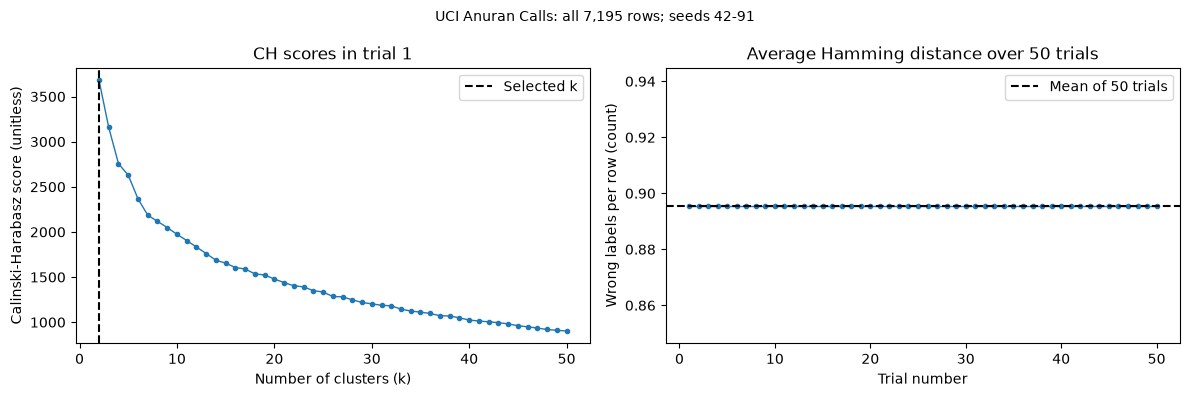

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
first_search = cluster_searches[0]
axes[0].plot(first_search['k'], first_search['CH_score'], marker='.', linewidth=1)
axes[0].axvline(trial_results.loc[0, 'k'], color='black', linestyle='--', label='Selected k')
axes[0].set(title='CH scores in trial 1', xlabel='Number of clusters (k)',
            ylabel='Calinski-Harabasz score (unitless)')
axes[0].legend()
axes[1].plot(trial_results['trial'], trial_results['Hamming_distance'], marker='.', linewidth=1)
axes[1].axhline(mc_summary.loc['Hamming_distance', 'mean'], color='black',
                linestyle='--', label='Mean of 50 trials')
axes[1].set(title='Average Hamming distance over 50 trials', xlabel='Trial number',
            ylabel='Wrong labels per row (count)')
axes[1].legend()
fig.suptitle('UCI Anuran Calls: all 7,195 rows; seeds 42-91', fontsize=10)
fig.tight_layout()
plt.show()
plt.close(fig)

## Conclusion

In [6]:
mean_distance = mc_summary.loc['Hamming_distance', 'mean']
std_distance = mc_summary.loc['Hamming_distance', 'std']
mean_loss = mc_summary.loc['Hamming_loss', 'mean']
std_loss = mc_summary.loc['Hamming_loss', 'std']
mean_score = mc_summary.loc['Hamming_score', 'mean']
std_score = mc_summary.loc['Hamming_score', 'std']
most_common_k = int(trial_results['k'].mode().iloc[0])
k_count = int((trial_results['k'] == most_common_k).sum())

display(Markdown(
    f'Across the 50 trials, the average Hamming distance was **{mean_distance:.6f}**, '
    f'with a standard deviation of **{std_distance:.6f}** wrong labels per row. '
    f'The mean Hamming loss was **{mean_loss:.6f}** (SD **{std_loss:.6f}**), '
    f'and the mean Hamming score was **{mean_score:.6f}** (SD **{std_score:.6f}**). '
    f'This means about **{100 * mean_score:.2f}%** of the individual labels matched the cluster majorities.\n\n'
    f'The most frequently selected number of clusters was **{most_common_k}**, '
    f'which was selected in **{k_count} of 50** trials. '
    'K-means groups rows by feature distance, so the clusters do not have to match the biological classes. '
    'Majority labels can also hide errors on rare classes. These scores describe how well the clusters '
    'line up with the labels in this dataset; they are not held-out classification scores.'
))

Across the 50 trials, the average Hamming distance was **0.895622**, with a standard deviation of **0.000000** wrong labels per row. The mean Hamming loss was **0.298541** (SD **0.000000**), and the mean Hamming score was **0.701459** (SD **0.000000**). This means about **70.15%** of the individual labels matched the cluster majorities.

The most frequently selected number of clusters was **2**, which was selected in **50 of 50** trials. K-means groups rows by feature distance, so the clusters do not have to match the biological classes. Majority labels can also hide errors on rare classes. These scores describe how well the clusters line up with the labels in this dataset; they are not held-out classification scores.

All 50 trials selected k=2 and gave the same number of incorrect labels, so the standard deviation is zero at the reported precision. This does not mean that randomness was removed: each trial used a different seed and five initializations per candidate k. It means the reported label error was stable under these settings. The CH criterion preferred two broad groups, which did not separate all of the biological classes.

# Question 3: Hierarchical Clustering

The four observations have the following dissimilarity matrix. I filled the diagonal with zeros because each observation has zero dissimilarity from itself.

$$D=\begin{pmatrix}
0 & 0.30 & 0.40 & 0.70\\
0.30 & 0 & 0.50 & 0.80\\
0.40 & 0.50 & 0 & 0.45\\
0.70 & 0.80 & 0.45 & 0
\end{pmatrix}.$$

I worked out the merge order below and used Python to draw the dendrograms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.spatial.distance import squareform

D = np.array([[0,    0.30, 0.40, 0.70],
              [0.30, 0,    0.50, 0.80],
              [0.40, 0.50, 0,    0.45],
              [0.70, 0.80, 0.45, 0]])

# linkage needs the pairwise distances, not rows of D as feature vectors.
distances = squareform(D)
complete_tree = linkage(distances, method='complete')
single_tree = linkage(distances, method='single')

# Label the observations and write the height of each merge on the plot.
def draw_tree(tree, title, cut_height=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    drawing = dendrogram(tree, labels=['1', '2', '3', '4'], ax=ax,
                         color_threshold=0, above_threshold_color='tab:blue')
    for x, y in zip(drawing['icoord'], drawing['dcoord']):
        middle = (x[1] + x[2]) / 2
        height = y[1]
        ax.annotate(f'{height:.2f}', (middle, height), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=10)
    if cut_height is not None:
        ax.axhline(cut_height, color='gray', linestyle='--',
                   label=f'Two-cluster cut: h = {cut_height:g}')
        ax.legend(loc='upper left', fontsize=9)
    ax.set(title=title, xlabel='Observation', ylabel='Dissimilarity (merge height)',
           ylim=(0, 0.92))
    fig.text(0.5, 0.01, 'Source: the four-observation dissimilarity matrix in the question',
             ha='center', fontsize=8)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()
    plt.close(fig)
    return drawing['ivl']

## 3(a) Complete linkage

Complete linkage uses the **largest** dissimilarity between points in two different clusters.

1. The smallest entry is $d(1,2)=0.30$, so observations 1 and 2 merge first.
2. After this merge, the distances are

   $$d(\{1,2\},3)=\max(0.40,0.50)=0.50,$$
   $$d(\{1,2\},4)=\max(0.70,0.80)=0.80,$$
   $$d(3,4)=0.45.$$

   The smallest is 0.45, so observations 3 and 4 merge next.
3. The distance between the two remaining clusters is

   $$d(\{1,2\},\{3,4\})=\max(0.40,0.70,0.50,0.80)=0.80.$$

So the merge heights are **0.30, 0.45, and 0.80**. The dashed line below is the cut used in part (c).

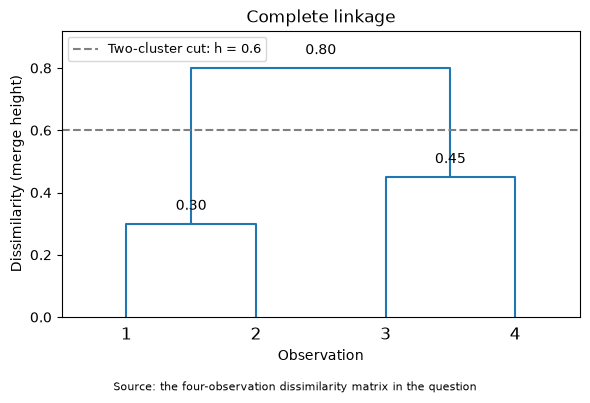

In [2]:
complete_leaves = draw_tree(complete_tree, 'Complete linkage', cut_height=0.60)

## 3(b) Single linkage

Single linkage uses the **smallest** dissimilarity between points in two different clusters.

1. Observations 1 and 2 again merge first at 0.30.
2. The new distances are

   $$d(\{1,2\},3)=\min(0.40,0.50)=0.40,$$
   $$d(\{1,2\},4)=\min(0.70,0.80)=0.70,$$
   $$d(3,4)=0.45.$$

   Since 0.40 is smallest, observation 3 joins $\{1,2\}$ next.
3. Finally,

   $$d(\{1,2,3\},4)=\min(0.70,0.80,0.45)=0.45.$$

So the merge heights are **0.30, 0.40, and 0.45**. The dashed line below is the cut used in part (d).

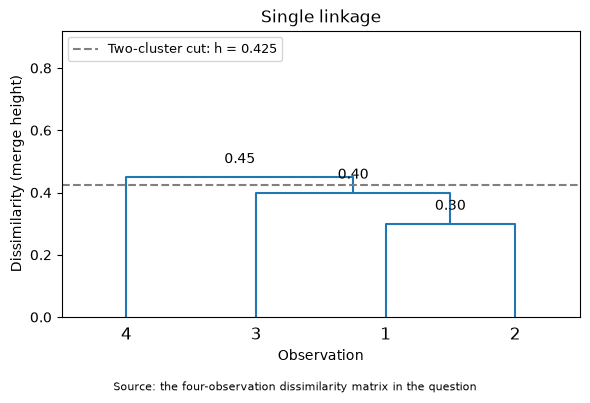

In [3]:
single_leaves = draw_tree(single_tree, 'Single linkage', cut_height=0.425)

## 3(c) Two clusters from complete linkage

I can cut at any height strictly between 0.45 and 0.80, for example **0.60**. At this point, the two pairs have formed but have not merged with each other.

The clusters are **$\{1,2\}$** and **$\{3,4\}$**.

## 3(d) Two clusters from single linkage

I can cut at any height strictly between 0.40 and 0.45, for example **0.425**. Observations 1, 2, and 3 have merged, while observation 4 is still separate.

The clusters are **$\{1,2,3\}$** and **$\{4\}$**.

In [4]:
# Check the two-cluster groups. The numeric cluster IDs are arbitrary.
for name, tree in [('Complete', complete_tree), ('Single', single_tree)]:
    group_ids = cut_tree(tree, n_clusters=2).ravel()
    groups = [(np.flatnonzero(group_ids == group) + 1).tolist()
              for group in np.unique(group_ids)]
    print(name, 'linkage:', groups)

Complete linkage: [[1, 2], [3, 4]]
Single linkage: [[1, 2, 3], [4]]


## 3(e) An equivalent dendrogram

I swapped the two leaves within each pair in the complete-linkage tree. This changes the left-to-right order from **1, 2, 3, 4** to **2, 1, 4, 3**.

The tree still merges $\{1,2\}$ at 0.30, $\{3,4\}$ at 0.45, and the two pairs at 0.80. Only the branch orientation changes, so it represents the same clustering. The horizontal order of the leaves does not change the merge heights or cluster membership.

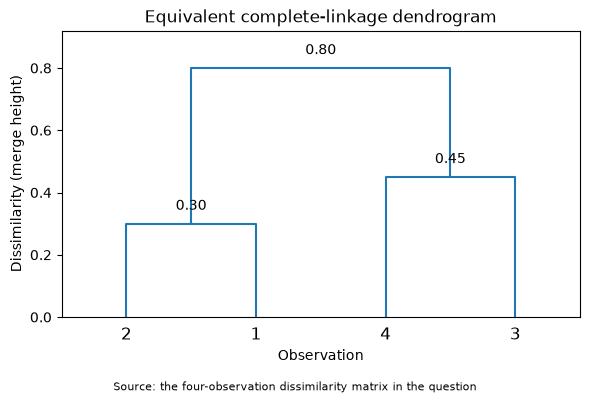

Original leaf order: ['1', '2', '3', '4']
Swapped leaf order: ['2', '1', '4', '3']


In [5]:
# The first two rows describe the two pairwise merges.
# Swapping their left and right children changes the drawing, not the clusters.
swapped_tree = complete_tree.copy()
swapped_tree[0, :2] = swapped_tree[0, :2][::-1]
swapped_tree[1, :2] = swapped_tree[1, :2][::-1]
swapped_leaves = draw_tree(swapped_tree, 'Equivalent complete-linkage dendrogram')
print('Original leaf order:', complete_leaves)
print('Swapped leaf order:', swapped_leaves)